# 31 — Training-budget convergence of the System I production posterior

Fixed controller law (2026-11-08); warm-start protocol chosen by notebook 29
(`results/29fx_selection.json`). This notebook refuses to start if that selection is flagged.

**Design.** One 160k simulation bank under the chosen protocol, simulated once. Budgets
5k, 10k, 20k, 40k, 80k, 160k × seeds 0–4 (nb29 measured ~20 s per 5k training run). Seed *s* trains on the first *N* rows
of its own permutation of the bank: nested across budgets for a fixed seed, different data
across seeds. A held-out test set (1000 SBC draws + 6 scenarios × 50 reps) from a reserved
seed. Each (N, seed) posterior and the 5-seed ensemble are scored with the nb29 suite.

## Convergence rule — fixed before results

Step N_k → N_{k+1} is **converged** if, for the ensemble at both budgets:
(a) |ΔCorr(α,β)| < 0.05 at each of Sc1, Sc2, Sc3, Sc4, Sc7 (Sc5 reported, not gated);
(b) |Δ 90% marginal coverage| < 0.02 for α and β;
(c) |ΔTARP deviation| < 0.01;
(d) at N_{k+1}: marginal KS p ≥ 0.01 for α and β on the **interior** SBC subset (true θ at
least 5% of the prior width from every edge), and TARP KS p ≥ 0.01 on the full set.
Full-set KS is reported alongside. *Amended after nb29, before any nb31 result:* in nb29 the
full-set α KS failed for every protocol at 5k while 90% coverage was ≈0.91; the interior gate
separates estimator bias from prior-edge truncation.

**Production budget** = N_{k+1} of the first converged step. If none converges: flag and review.
**Ensemble vs single seed**: ensemble if its TARP deviation ≤ the median single-seed TARP
deviation at that budget, else the single seed with the lowest TARP deviation.
Result: `results/31_production.json`, loaded downstream with `load_production_posterior()`.

**Running this notebook.** Execute top to bottom from `notebooks/system_I`. Training is the
long part (seconds at 5k, of order 10–30 min per seed at 160k). With `PARALLEL_TRAINING`,
seed groups train in subprocesses launched from this folder. Re-running resumes.


In [1]:
import json, os, sys, time, subprocess
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", \
    f"execute this notebook from notebooks/system_I (cwd is {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
os.environ["CSTR_SENSOR_MODEL"] = "N0"   # N0 run; default model is N3 since 2026-11-09
import importlib, system_I_config, ws_protocols, ws_eval, nb29_ws_study, nb31_budget_convergence
for _m in (system_I_config, ws_protocols, ws_eval, nb29_ws_study, nb31_budget_convergence):
    importlib.reload(_m)
B = nb31_budget_convergence
assert B.SENSOR == "N0", B.SENSOR
R, FIGS = ROOT / "results", ROOT / "figures"

# ---- run switches -----------------------------------------------------------------
BUDGETS = B.DEFAULT_BUDGETS          # add 80_000 only if the decision below asks for it
PARALLEL_TRAINING = True
SEED_GROUPS = [[0, 1], [2, 3], [4]]  # one subprocess per group
THREADS = 3
T0 = time.time()

PROTOCOL = B.protocol()              # stops here if nb29's selection is missing or flagged
print("protocol from nb29:", PROTOCOL)

nb29 selection was flagged; proceeding with user-approved P1b: Flag caused by full-set alpha SBC failing for every protocol incl. matched pairs (5k-budget estimator limit, handled by nb31); P1b best on all other P2-column calibration measures.
protocol from nb29: P1b


## 0. Scenario catalogue used for the test set
The test set's scenario grid is read from `cstr_sbi.scenarios.SCENARIO_CONFIGS`. nb29 found
Sc5's β on the prior edge and Sc2 saturated; settle any catalogue change **before** section 1
(the test set is simulated once and cached).

In [2]:
from cstr_sbi.scenarios import SCENARIO_CONFIGS
import ws_eval as we
display(pd.DataFrame([{"scenario": k, "alpha": SCENARIO_CONFIGS[k].alpha, "beta": SCENARIO_CONFIGS[k].beta,
                       "drift_T": SCENARIO_CONFIGS[k].drift_T,
                       "on_prior_edge": bool(np.isclose([SCENARIO_CONFIGS[k].alpha, SCENARIO_CONFIGS[k].beta],
                                                        np.r_[we.LO, we.HI].reshape(2, 2)).any())}
                      for k in we.EVAL_SCENARIOS]))

,scenario,alpha,beta,drift_T,on_prior_edge
0,Sc1_closed_healthy,1.00,1.00,0.0,False
1,Sc2_closed_fouling,1.00,0.85,0.0,False
2,Sc3_closed_decay,0.70,1.00,0.0,False
3,Sc4_closed_combined,0.85,0.85,0.0,False
4,Sc5_closed_saturated,1.00,0.50,0.0,False
5,Sc7_closed_drift,1.00,0.85,2.0,False


## 1. Simulation bank (160k) and held-out test set

In [3]:
B.stage_bank(PROTOCOL)
B.stage_test(PROTOCOL)

chunk 0: 27s
chunk 1: 28s
chunk 2: 27s
chunk 3: 25s
chunk 4: 26s
chunk 5: 26s
chunk 6: 26s
chunk 7: 29s
chunk 8: 26s
chunk 9: 26s
chunk 10: 26s
chunk 11: 26s
chunk 12: 27s
chunk 13: 26s
chunk 14: 26s
chunk 15: 25s


## 2. Train budgets × seeds

In [5]:
budgets_arg = ",".join(str(b) for b in BUDGETS)
if PARALLEL_TRAINING:
    procs = []
    for g in SEED_GROUPS:
        seeds = ",".join(str(s) for s in g)
        log = open(R / f"31_train_seeds{seeds.replace(',', '_')}.log", "w")
        procs.append(subprocess.Popen(
            [sys.executable, str(ROOT / "scripts" / "nb31_budget_convergence.py"), "train",
             "--protocol", PROTOCOL, "--budgets", budgets_arg, "--seeds", seeds, "--threads", str(THREADS)],
            cwd=NB_DIR, stdout=log, stderr=subprocess.STDOUT))
    codes = [p.wait() for p in procs]
    assert all(c == 0 for c in codes), f"training subprocess failed: {codes} (see results/31_train_*.log)"
else:
    B.stage_train(PROTOCOL, BUDGETS, B.SEEDS, THREADS)
print(sorted(f.name for f in B.OUT.glob("post_*.pkl")))

['post_P1b_n10000_s0.pkl', 'post_P1b_n10000_s1.pkl', 'post_P1b_n10000_s2.pkl', 'post_P1b_n10000_s3.pkl', 'post_P1b_n10000_s4.pkl', 'post_P1b_n160000_s0.pkl', 'post_P1b_n160000_s1.pkl', 'post_P1b_n160000_s2.pkl', 'post_P1b_n160000_s3.pkl', 'post_P1b_n160000_s4.pkl', 'post_P1b_n20000_s0.pkl', 'post_P1b_n20000_s1.pkl', 'post_P1b_n20000_s2.pkl', 'post_P1b_n20000_s3.pkl', 'post_P1b_n20000_s4.pkl', 'post_P1b_n40000_s0.pkl', 'post_P1b_n40000_s1.pkl', 'post_P1b_n40000_s2.pkl', 'post_P1b_n40000_s3.pkl', 'post_P1b_n40000_s4.pkl', 'post_P1b_n5000_s0.pkl', 'post_P1b_n5000_s1.pkl', 'post_P1b_n5000_s2.pkl', 'post_P1b_n5000_s3.pkl', 'post_P1b_n5000_s4.pkl', 'post_P1b_n80000_s0.pkl', 'post_P1b_n80000_s1.pkl', 'post_P1b_n80000_s2.pkl', 'post_P1b_n80000_s3.pkl', 'post_P1b_n80000_s4.pkl']


## 3. Evaluate every (budget, seed) posterior and the ensembles

In [6]:
B.stage_eval(PROTOCOL)

5000 0 {'ks_p_a': 0.0, 'ks_p_b': 0.066, 'tarp_ks_p': 0.019, 'tarp_dev': 0.046, 'cov90_a': 0.907, 'cov90_b': 0.868, 'corr_Sc4': 0.049}
5000 1 {'ks_p_a': 0.0, 'ks_p_b': 0.026, 'tarp_ks_p': 0.057, 'tarp_dev': 0.042, 'cov90_a': 0.85, 'cov90_b': 0.861, 'corr_Sc4': 0.015}
5000 2 {'ks_p_a': 0.006, 'ks_p_b': 0.068, 'tarp_ks_p': 0.323, 'tarp_dev': 0.028, 'cov90_a': 0.943, 'cov90_b': 0.884, 'corr_Sc4': 0.055}
5000 3 {'ks_p_a': 0.015, 'ks_p_b': 0.0, 'tarp_ks_p': 0.079, 'tarp_dev': 0.038, 'cov90_a': 0.909, 'cov90_b': 0.852, 'corr_Sc4': -0.0}
5000 4 {'ks_p_a': 0.048, 'ks_p_b': 0.007, 'tarp_ks_p': 0.406, 'tarp_dev': 0.025, 'cov90_a': 0.924, 'cov90_b': 0.844, 'corr_Sc4': 0.01}
5000 ensemble {'ks_p_a': 0.0, 'ks_p_b': 0.435, 'tarp_ks_p': 0.452, 'tarp_dev': 0.027, 'cov90_a': 0.95, 'cov90_b': 0.882, 'corr_Sc4': 0.036}
10000 0 {'ks_p_a': 0.001, 'ks_p_b': 0.185, 'tarp_ks_p': 0.04, 'tarp_dev': 0.042, 'cov90_a': 0.927, 'cov90_b': 0.854, 'corr_Sc4': 0.037}
10000 1 {'ks_p_a': 0.0, 'ks_p_b': 0.026, 'tarp_ks_p':

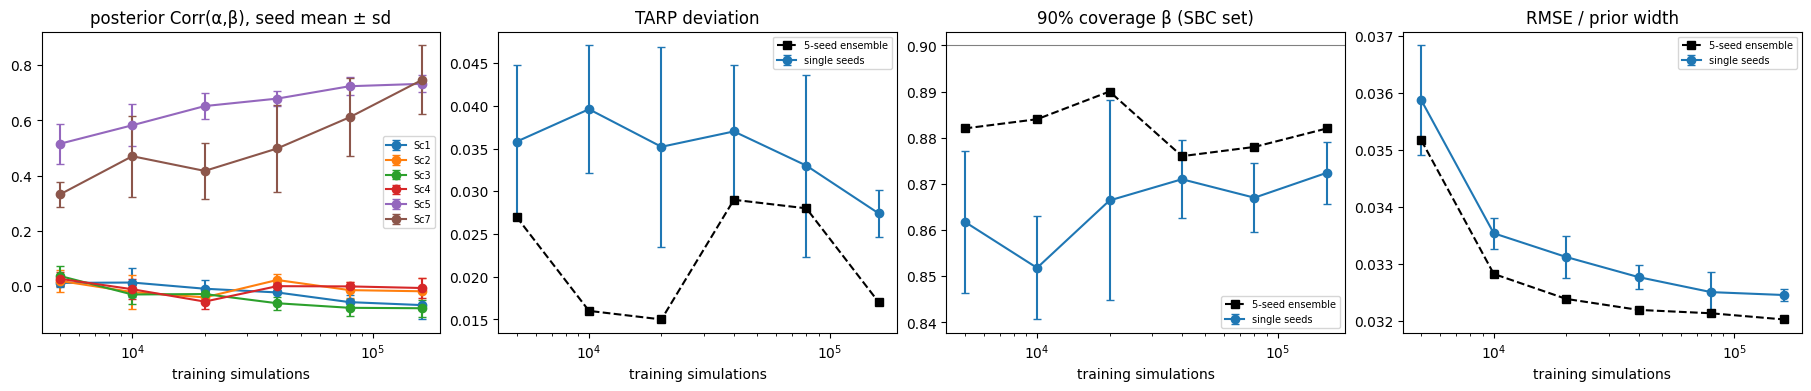

,ks_p_a,ks_p_b,ks_p_a_interior,ks_p_b_interior,tarp_ks_p,tarp_dev,cov90_a,cov90_b,rmse_norm,macro_f1,leak_sbc_mean,corr_Sc1,corr_Sc2,corr_Sc3,corr_Sc4,corr_Sc7
budget,,,,,,,,,,,,,,,,
5000,0.000,0.435,0.000,0.891,0.452,0.027,0.950,0.882,0.035,0.992,0.020,0.018,0.027,0.030,0.036,0.304
10000,0.005,0.615,0.005,0.371,0.930,0.016,0.943,0.884,0.033,0.987,0.013,0.011,-0.023,-0.013,-0.012,0.316
20000,0.007,0.750,0.011,0.328,0.930,0.015,0.944,0.890,0.032,0.982,0.012,0.014,-0.027,-0.024,-0.042,0.346
40000,0.009,0.182,0.012,0.814,0.252,0.029,0.940,0.876,0.032,0.982,0.007,-0.015,-0.011,-0.038,-0.010,0.320
80000,0.076,0.103,0.036,0.568,0.323,0.028,0.936,0.878,0.032,0.987,0.006,-0.052,-0.022,-0.078,-0.008,0.572
160000,0.037,0.770,0.024,0.837,0.856,0.017,0.932,0.882,0.032,0.982,0.007,-0.063,-0.041,-0.081,-0.011,0.703


In [7]:
m = pd.read_csv(R / "31_metrics.csv"); m["member"] = m["member"].astype(str)
ens, single = m[m.member == "ensemble"].sort_values("budget"), m[m.member != "ensemble"]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), constrained_layout=True)
for sc in ["Sc1", "Sc2", "Sc3", "Sc4", "Sc5", "Sc7"]:
    g = single.groupby("budget")[f"corr_{sc}"]
    axes[0].errorbar(g.mean().index, g.mean(), yerr=g.std(), marker="o", capsize=3, label=sc)
axes[0].set_title("posterior Corr(α,β), seed mean ± sd"); axes[0].legend(fontsize=7)
for k, ax, t in [("tarp_dev", axes[1], "TARP deviation"), ("cov90_b", axes[2], "90% coverage β (SBC set)"),
                 ("rmse_norm", axes[3], "RMSE / prior width")]:
    g = single.groupby("budget")[k]
    ax.errorbar(g.mean().index, g.mean(), yerr=g.std(), marker="o", capsize=3, label="single seeds")
    ax.plot(ens.budget, ens[k], "k--s", label="5-seed ensemble"); ax.set_title(t); ax.legend(fontsize=7)
for ax in axes:
    ax.set_xscale("log"); ax.set_xlabel("training simulations")
axes[2].axhline(0.9, color="grey", lw=0.8)
fig.savefig(FIGS / "31_budget_convergence.png", dpi=150); plt.show()
display(ens.set_index("budget")[["ks_p_a", "ks_p_b", "ks_p_a_interior", "ks_p_b_interior", "tarp_ks_p", "tarp_dev", "cov90_a", "cov90_b",
                                 "rmse_norm", "macro_f1", "leak_sbc_mean",
                                 "corr_Sc1", "corr_Sc2", "corr_Sc3", "corr_Sc4", "corr_Sc7"]].round(3))

### Per-scenario classification accuracy and β coverage (ensemble)
Fraction of the 50 test windows per scenario assigned to the true fault class (threshold
0.90), and the 90% coverage of β at the truth. Sc2 (β = 0.85) sits at the midpoint of the
unsaturated fouling band, 0.05 below the threshold, so its accuracy is expected below ~100%.

In [8]:
scn = pd.read_csv(R / "31_scenarios.csv"); scn["member"] = scn["member"].astype(str)
e_sc = scn[scn.member == "ensemble"]
display(e_sc.pivot_table(index="scenario", columns="budget", values="class_acc").round(3))
display(e_sc.pivot_table(index="scenario", columns="budget", values="cov90_truth_b").round(3))
display(e_sc.pivot_table(index="scenario", columns="budget", values="beta_hat").round(3))

budget,5000,10000,20000,40000,80000,160000
scenario,,,,,,
Sc1_closed_healthy,1.00,1.00,1.00,1.00,1.00,1.00
Sc2_closed_fouling,0.98,0.98,0.98,0.98,0.98,0.98
Sc3_closed_decay,1.00,1.00,1.00,1.00,1.00,1.00
Sc4_closed_combined,0.98,0.96,0.94,0.94,0.96,0.94
Sc5_closed_saturated,1.00,1.00,1.00,1.00,1.00,1.00
Sc7_closed_drift,1.00,1.00,1.00,1.00,1.00,1.00


budget,5000,10000,20000,40000,80000,160000
scenario,,,,,,
Sc1_closed_healthy,0.98,0.96,0.98,0.96,0.96,0.98
Sc2_closed_fouling,0.96,0.94,0.94,0.96,0.96,0.96
Sc3_closed_decay,0.94,0.98,0.94,0.98,0.98,0.98
Sc4_closed_combined,0.94,0.90,0.90,0.90,0.94,0.94
Sc5_closed_saturated,0.92,0.90,0.90,0.88,0.90,0.90
Sc7_closed_drift,0.04,0.02,0.00,0.06,0.48,0.56


budget,5000,10000,20000,40000,80000,160000
scenario,,,,,,
Sc1_closed_healthy,0.994,0.994,0.995,0.990,0.988,0.993
Sc2_closed_fouling,0.851,0.853,0.853,0.850,0.851,0.853
Sc3_closed_decay,1.003,1.002,1.001,0.995,0.995,0.998
Sc4_closed_combined,0.855,0.857,0.858,0.854,0.854,0.855
Sc5_closed_saturated,0.519,0.513,0.512,0.516,0.516,0.513
Sc7_closed_drift,0.586,0.584,0.588,0.564,0.635,0.665


### α calibration and efficiency against the Cramér–Rao bound
Full-set vs interior α SBC KS by budget, and the posterior sd at each scenario divided by the
29-D-summary Cramér–Rao bound from nb29 E2 (same protocol). A ratio well above 1 means the
estimator is not yet extracting the information in the summaries; it should approach ~1 as the
budget grows (exactly 1 only if the summaries' likelihood were Gaussian).

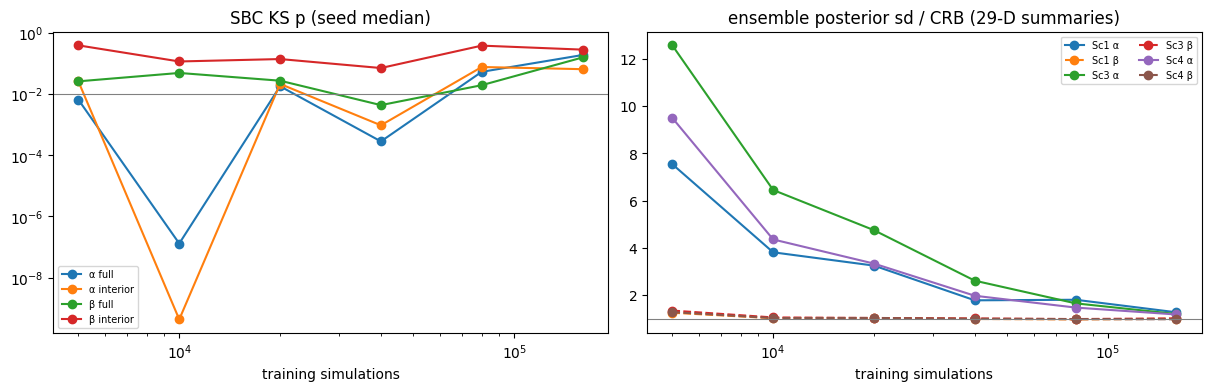

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
for k, lab in [("ks_p_a", "α full"), ("ks_p_a_interior", "α interior"), ("ks_p_b", "β full"), ("ks_p_b_interior", "β interior")]:
    g = single.groupby("budget")[k].median()
    axes[0].plot(g.index, g.values, "o-", label=lab)
axes[0].axhline(0.01, color="grey", lw=0.8); axes[0].set_yscale("log"); axes[0].set_xscale("log")
axes[0].set_title("SBC KS p (seed median)"); axes[0].legend(fontsize=7); axes[0].set_xlabel("training simulations")
crb = pd.read_csv(R / "29fx_e2_fim.csv")
crb = crb[(crb.protocol == PROTOCOL) & (crb.representation == "summaries_fullcov")]
pts = {"Sc1": (1.0, 1.0), "Sc2": (1.0, 0.7), "Sc3": (0.7, 1.0), "Sc4": (0.85, 0.85)}
for sc, (a, b) in pts.items():
    cfg = [k for k in we.EVAL_SCENARIOS if k.startswith(sc + "_")][0]
    if not (np.isclose(SCENARIO_CONFIGS[cfg].alpha, a) and np.isclose(SCENARIO_CONFIGS[cfg].beta, b)):
        continue            # catalogue changed since nb29: no matching CRB point
    c = crb[crb.point == sc].iloc[0]
    for par, col, cr, ls in [("α", f"sda_{sc}", c.crb_sd_a, "-"), ("β", f"sdb_{sc}", c.crb_sd_b, "--")]:
        if col in ens:
            axes[1].plot(ens.budget, ens[col] / cr, "o" + ls, label=f"{sc} {par}")
axes[1].axhline(1, color="grey", lw=0.8); axes[1].set_xscale("log"); axes[1].set_xlabel("training simulations")
axes[1].set_title("ensemble posterior sd / CRB (29-D summaries)"); axes[1].legend(fontsize=7, ncol=2)
fig.savefig(FIGS / "31_alpha_calibration_efficiency.png", dpi=150); plt.show()

## 4. Decision (applies the pre-set rule)

In [10]:
B.stage_decide(PROTOCOL)
res = json.loads((R / "31_production.json").read_text())
display(pd.DataFrame(res["steps"]).drop(columns=["dcorr"]))
print({k: v for k, v in res.items() if k != "steps"})
if res["flag"]:
    print("FLAG:", res["flag"])

{'from': 5000, 'to': 10000, 'max_dcorr': 0.0502449805053263, 'dcorr': {'Sc1': 0.006257634637756899, 'Sc2': 0.0502449805053263, 'Sc3': 0.043265896806091095, 'Sc4': 0.0473719966662166, 'Sc7': 0.011652398065773784}, 'a_corr': False, 'b_cov': True, 'c_tarp': False, 'd_calib': False, 'ks_a_full': 0.0048535289781643, 'ks_b_full': 0.6148439612572029, 'ks_a_interior': 0.0052717136065447, 'ks_b_interior': 0.3705854575268349, 'converged': False}
{'from': 10000, 'to': 20000, 'max_dcorr': 0.0306490507895706, 'dcorr': {'Sc1': 0.0023349375568562005, 'Sc2': 0.0035404960511866007, 'Sc3': 0.0107084516900815, 'Sc4': 0.0306490507895706, 'Sc7': 0.029775558870448415}, 'a_corr': True, 'b_cov': True, 'c_tarp': True, 'd_calib': True, 'ks_a_full': 0.0069444324547924, 'ks_b_full': 0.7502907497113545, 'ks_a_interior': 0.0108014291904546, 'ks_b_interior': 0.327690815785766, 'converged': True}
{'from': 20000, 'to': 40000, 'max_dcorr': 0.0321387230487859, 'dcorr': {'Sc1': 0.028195903165091803, 'Sc2': 0.016302714209

,from,to,max_dcorr,a_corr,b_cov,c_tarp,d_calib,ks_a_full,ks_b_full,ks_a_interior,ks_b_interior,converged
0,5000,10000,0.050245,False,True,False,False,0.004854,0.614844,0.005272,0.370585,False
1,10000,20000,0.030649,True,True,True,True,0.006944,0.750291,0.010801,0.327691,True
2,20000,40000,0.032139,True,True,False,True,0.008554,0.181856,0.011583,0.813684,False
3,40000,80000,0.252074,False,True,True,True,0.075630,0.102826,0.036339,0.567681,False
4,80000,160000,0.130678,False,True,False,True,0.036948,0.770439,0.023918,0.837067,False


{'protocol': 'P1b', 'production_budget': 20000, 'use_ensemble': True, 'members': ['/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/results/31_budget/post_P1b_n20000_s0.pkl', '/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/results/31_budget/post_P1b_n20000_s1.pkl', '/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/results/31_budget/post_P1b_n20000_s2.pkl', '/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/results/31_budget/post_P1b_n20000_s3.pkl', '/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/results/31_budget/post_P1b_n20000_s4.pkl'], 'flag': None, 'rule': 'see docstring of scripts/nb31_budget_convergence.py (fixed before results)'}


## 4b. Amended decision (rule v2) — written after seeing the results, approved by the user

The v1 rule above selected **20k**. Three flaws were found in it: (1) it took the first
converged step without requiring later steps to stay converged (20k→40k fails); (2) it gated on
Sc7, which is misspecified by design (+2 K sensor drift absent from the model), so its posterior
extrapolates and is not expected to converge; (3) it had no precision criterion, while α's
posterior sd at 20k was ~3.5× its Cramér–Rao bound and still halving per doubling.
Rule v2 drops Sc7 from the correlation gate and adds a precision criterion (< 10% change in
posterior sd) and persistence. No step qualifies (α precision still improves ~30% per doubling),
so v2 takes the **largest budget passing calibration: 160k, 5-seed ensemble**. Both choices are
kept in `results/31_production.json`, with the approval record. Note (not changed): criterion (c)
uses a TARP-deviation threshold (0.01) below that statistic's own sampling noise (~0.04).
Report both in the paper: the headline results do not depend on 20k vs 160k; only α precision does.

In [ ]:
res_v2 = B.stage_decide_amended(
    PROTOCOL, approve=True, approved_by="user (Simone Casolo), in conversation with Claude",
    reason=("User approved 2026-11-08: v1 rule selected 20k but was flawed (no persistence, gated on the "
            "misspecified Sc7, no precision criterion); 160k 5-seed ensemble is calibrated and brings alpha "
            "within ~1.2x of its summary-statistic Cramer-Rao bound (beta at the bound)."))
display(pd.DataFrame(res_v2["rule_v2_steps"]))
print("production:", res_v2["production_budget"], "ensemble" if res_v2["use_ensemble"] else "single",
      "| v1 would have chosen:", res_v2["rule_v1_choice"])

## 5. Smoke test of the production posterior as downstream notebooks will load it

In [ ]:
import torch
post, info = B.load_production_posterior()
test = we.load_npz(B.OUT / f"test_{PROTOCOL}.npz")
x = test["x_sc"][test["sc_name"] == "Sc4_closed_combined"][:1]
s = post.sample((5000,), x=torch.as_tensor(x[0], dtype=torch.float32),
                show_progress_bars=False, reject_outside_prior=False).numpy()
print(info["protocol"], info["production_budget"], "ensemble" if info["use_ensemble"] else "single",
      "| Sc4 mean", s.mean(0).round(3), "corr", round(float(np.corrcoef(s.T)[0, 1]), 3))
print(f"notebook wall time {(time.time() - T0) / 60:.1f} min")